Setup stuff

In [20]:
import numpy as np
import pandas as pd
import bambi as bmb
import arviz as az
import scipy.stats as st
import matplotlib.pyplot as plt

In [21]:
df = pd.read_csv("domestic_well_radon.csv")
df = df.dropna(subset=["log_radon", "well_depth_ft", "lithology", "aquifer"])
df["log_depth"] = np.log(df["well_depth_ft"])
df["centered_log_depth"] = (df["log_depth"] - df["log_depth"].mean())
df = df[["log_radon", "centered_log_depth", "lithology", "aquifer"]]
df.dropna()
print("Number of lithologies:", df["lithology"].nunique())
print("Number of aquifers:", df["aquifer"].nunique())
print("Wells with complete data:", len(df))
print(df.groupby("lithology")["log_radon"].agg(["count", "mean", "std", "min", "max"]))
df.head()

Number of lithologies: 9
Number of aquifers: 42
Wells with complete data: 2077
                                                    count      mean       std  \
lithology                                                                       
Basalt and other volcanic-rock aquifers                15  5.507268  1.458491   
Carbonate-rock                                        200  5.713703  1.171247   
Crystalline-rock                                      282  7.601792  1.301691   
Glacial                                               311  5.723762  0.902455   
Sandstone                                             276  6.592041  1.085284   
Sandstone and carbonate-rock                           41  5.933747  0.764686   
Semi-consolidated sand                                234  5.423905  0.825127   
Unconsolidated sand and gravel (non-glacial)          689  6.233652  0.677248   
Unconsolidated sand and gravel (non-glacial) an...     29  5.724681  0.480025   

                             

,log_radon,centered_log_depth,lithology,aquifer
0,5.950643,-1.004532,Unconsolidated sand and gravel (non-glacial),Surficial
1,5.880533,-0.229892,Unconsolidated sand and gravel (non-glacial),Surficial
2,6.865891,-0.880480,Unconsolidated sand and gravel (non-glacial),Surficial
3,7.259820,-1.103623,Unconsolidated sand and gravel (non-glacial),Surficial
4,7.028201,-1.062801,Unconsolidated sand and gravel (non-glacial),Surficial


Priors (change later):

In [26]:
intercept = {
    "Intercept": bmb.Prior("Normal", mu=6.0, sigma=2.0)
}

depth = {
    "centered_log_depth": bmb.Prior("Normal", mu=0.0, sigma=1.0),
}

sigma = {
    "sigma": bmb.Prior("HalfNormal", sigma=1.0)
}

lithology_intercept = {
    "1|lithology": bmb.Prior("Normal", mu=0.0, sigma=bmb.Prior("HalfNormal", sigma=1.0))
}

aquifier_intercept = {
    "1|aquifer": bmb.Prior("Normal", mu=0.0, sigma=bmb.Prior("HalfNormal", sigma=1.0)),
}

varying_sigma_prior = {
    "sigma": {
        "lithology": bmb.Prior("Normal", mu=0.0, sigma=1.0),
    }
}
lithology_specific_depth =  {
    "centered_log_depth|lithology": bmb.Prior(
        "Normal", mu=0.0, sigma=bmb.Prior("HalfNormal", sigma=0.5)
    )
}

nu = {
    "nu": bmb.Prior("Gamma", alpha=2, beta=0.1)
}

pooled_priors = intercept | depth | sigma

aquifer_hierarchical_priors = intercept | depth | sigma | aquifier_intercept

combined_hierarchical_priors = intercept | depth | sigma | lithology_intercept | aquifier_intercept

combined_varying_sigma_hierarchical_priors = intercept | depth | lithology_intercept | aquifier_intercept | varying_sigma_prior
 
lithology_specific_depth_coefficient_priors = intercept | depth | sigma | lithology_specific_depth | lithology_intercept | aquifier_intercept

combined_varying_sigma_hierarchical_priors_t = intercept | depth | lithology_intercept | aquifier_intercept | varying_sigma_prior | nu

pooled_priors_t = intercept | depth | sigma | nu

Model. Hierarchical, with intercept from lithology & aquifer

In [27]:
combined_hierarchical_model = bmb.Model(
    formula = bmb.Formula(
        "log_radon ~ 1 + centered_log_depth + (1 | lithology) + (1 | aquifer)",
    ),
    data=df,
    priors=combined_hierarchical_priors,
)

combined_varying_sigma_hierarchical_model = bmb.Model(
    formula = bmb.Formula(
        "log_radon ~ 1 + centered_log_depth + (1 | lithology) + (1 | aquifer)",
        "sigma ~ 0 + lithology",
    ),
    data=df,
    priors=combined_varying_sigma_hierarchical_priors,
)


combined_varying_sigma_hierarchical_model_t = bmb.Model(
    bmb.Formula(
        "log_radon ~ 1 + centered_log_depth + (1 | lithology) + (1 | aquifer)",
        "sigma ~ 0 + lithology",
    ),
    data=df,
    family="t",
    priors=combined_varying_sigma_hierarchical_priors_t,
)
aquifer_hierarchical_model = bmb.Model(
    formula = bmb.Formula(
        "log_radon ~ 1 + centered_log_depth + (1 | aquifer)",
    ),
    data=df,
    priors=aquifer_hierarchical_priors,
)

lithology_specific_depth_coefficient_model = bmb.Model(
    formula = bmb.Formula(
        "log_radon ~ 1 + centered_log_depth + (centered_log_depth | lithology) + (1 | lithology) + (1 | aquifer)",
    ),
    data=df,
    priors=lithology_specific_depth_coefficient_priors,
)

pooled_model = bmb.Model(
    formula = bmb.Formula(
        "log_radon ~ 1 + centered_log_depth",
    ),
    data=df,
    priors=pooled_priors,
)

pooled_model_t = bmb.Model(
    bmb.Formula("log_radon ~ 1 + centered_log_depth"),
    data=df,
    family="t",
    priors=pooled_priors_t,
)

In [28]:
combined_hierarchical_fit = combined_hierarchical_model.fit(target_accept=0.95, idata_kwargs={"log_likelihood": True})


Initializing NUTS using jitter+adapt_diag...
Multiprocess sampling (4 chains in 4 jobs)
NUTS: [sigma, Intercept, centered_log_depth, 1|lithology_sigma, 1|lithology_offset, 1|aquifer_sigma, 1|aquifer_offset]


/home/oscar/school/bda/bda-project/.venv/lib/python3.12/site-packages/rich/live.py:260: UserWarning: install 
"ipywidgets" for Jupyter support
  warnings.warn('install "ipywidgets" for Jupyter support')

/home/oscar/school/bda/bda-project/.venv/lib/python3.12/site-packages/pymc/sampling/mcmc.py:1185: FutureWarning: Passing `log_likelihood` via `idata_kwargs` is deprecated and will be removed in future versions. Call `pm.compute_log_likelihood(idata)` instead.
  return _sample_return(
Sampling 4 chains for 1_000 tune and 1_000 draw iterations (4_000 + 4_000 draws total) took 14 seconds.


In [29]:
combined_varying_sigma_hierarchical_fit = combined_varying_sigma_hierarchical_model.fit(target_accept=0.95, idata_kwargs={"log_likelihood": True})


Initializing NUTS using jitter+adapt_diag...
Multiprocess sampling (4 chains in 4 jobs)
NUTS: [Intercept, centered_log_depth, 1|lithology_sigma, 1|lithology_offset, 1|aquifer_sigma, 1|aquifer_offset, sigma_lithology]


/home/oscar/school/bda/bda-project/.venv/lib/python3.12/site-packages/rich/live.py:260: UserWarning: install 
"ipywidgets" for Jupyter support
  warnings.warn('install "ipywidgets" for Jupyter support')

/home/oscar/school/bda/bda-project/.venv/lib/python3.12/site-packages/pymc/sampling/mcmc.py:1185: FutureWarning: Passing `log_likelihood` via `idata_kwargs` is deprecated and will be removed in future versions. Call `pm.compute_log_likelihood(idata)` instead.
  return _sample_return(
Sampling 4 chains for 1_000 tune and 1_000 draw iterations (4_000 + 4_000 draws total) took 26 seconds.


In [30]:
combined_varying_sigma_hierarchical_fit_t = combined_varying_sigma_hierarchical_model_t.fit(target_accept=0.95, idata_kwargs={"log_likelihood": True})

Initializing NUTS using jitter+adapt_diag...
Multiprocess sampling (4 chains in 4 jobs)
NUTS: [nu, Intercept, centered_log_depth, 1|lithology_sigma, 1|lithology_offset, 1|aquifer_sigma, 1|aquifer_offset, sigma_lithology]


/home/oscar/school/bda/bda-project/.venv/lib/python3.12/site-packages/rich/live.py:260: UserWarning: install 
"ipywidgets" for Jupyter support
  warnings.warn('install "ipywidgets" for Jupyter support')

/home/oscar/school/bda/bda-project/.venv/lib/python3.12/site-packages/pymc/sampling/mcmc.py:1185: FutureWarning: Passing `log_likelihood` via `idata_kwargs` is deprecated and will be removed in future versions. Call `pm.compute_log_likelihood(idata)` instead.
  return _sample_return(
Sampling 4 chains for 1_000 tune and 1_000 draw iterations (4_000 + 4_000 draws total) took 43 seconds.


In [31]:
aquifer_hierarchical_fit =  aquifer_hierarchical_model.fit(draws=4000, target_accept=0.8, idata_kwargs={"log_likelihood": True})

Initializing NUTS using jitter+adapt_diag...
Multiprocess sampling (4 chains in 4 jobs)
NUTS: [sigma, Intercept, centered_log_depth, 1|aquifer_sigma, 1|aquifer_offset]


/home/oscar/school/bda/bda-project/.venv/lib/python3.12/site-packages/rich/live.py:260: UserWarning: install 
"ipywidgets" for Jupyter support
  warnings.warn('install "ipywidgets" for Jupyter support')

/home/oscar/school/bda/bda-project/.venv/lib/python3.12/site-packages/pymc/sampling/mcmc.py:1185: FutureWarning: Passing `log_likelihood` via `idata_kwargs` is deprecated and will be removed in future versions. Call `pm.compute_log_likelihood(idata)` instead.
  return _sample_return(
Sampling 4 chains for 1_000 tune and 4_000 draw iterations (4_000 + 16_000 draws total) took 7 seconds.


In [32]:
lithology_specific_depth_coefficient_fit =  lithology_specific_depth_coefficient_model.fit(target_accept=0.95, idata_kwargs={"log_likelihood": True})

Initializing NUTS using jitter+adapt_diag...
Multiprocess sampling (4 chains in 4 jobs)
NUTS: [sigma, Intercept, centered_log_depth, 1|lithology_sigma, 1|lithology_offset, centered_log_depth|lithology_sigma, centered_log_depth|lithology_offset, 1|aquifer_sigma, 1|aquifer_offset]


/home/oscar/school/bda/bda-project/.venv/lib/python3.12/site-packages/rich/live.py:260: UserWarning: install 
"ipywidgets" for Jupyter support
  warnings.warn('install "ipywidgets" for Jupyter support')

/home/oscar/school/bda/bda-project/.venv/lib/python3.12/site-packages/pymc/sampling/mcmc.py:1185: FutureWarning: Passing `log_likelihood` via `idata_kwargs` is deprecated and will be removed in future versions. Call `pm.compute_log_likelihood(idata)` instead.
  return _sample_return(
Sampling 4 chains for 1_000 tune and 1_000 draw iterations (4_000 + 4_000 draws total) took 16 seconds.


In [33]:
pooled_fit = pooled_model.fit(target_accept=0.8, idata_kwargs={"log_likelihood": True})

Initializing NUTS using jitter+adapt_diag...
Multiprocess sampling (4 chains in 4 jobs)
NUTS: [sigma, Intercept, centered_log_depth]


/home/oscar/school/bda/bda-project/.venv/lib/python3.12/site-packages/rich/live.py:260: UserWarning: install 
"ipywidgets" for Jupyter support
  warnings.warn('install "ipywidgets" for Jupyter support')

/home/oscar/school/bda/bda-project/.venv/lib/python3.12/site-packages/pymc/step_methods/hmc/quadpotential.py:321: RuntimeWarning: overflow encountered in dot
  return 0.5 * np.dot(x, v_out)
/home/oscar/school/bda/bda-project/.venv/lib/python3.12/site-packages/pymc/step_methods/hmc/quadpotential.py:321: RuntimeWarning: overflow encountered in dot
  return 0.5 * np.dot(x, v_out)
/home/oscar/school/bda/bda-project/.venv/lib/python3.12/site-packages/pymc/step_methods/hmc/quadpotential.py:321: RuntimeWarning: overflow encountered in dot
  return 0.5 * np.dot(x, v_out)


/home/oscar/school/bda/bda-project/.venv/lib/python3.12/site-packages/pymc/sampling/mcmc.py:1185: FutureWarning: Passing `log_likelihood` via `idata_kwargs` is deprecated and will be removed in future versions. Call `pm.compute_log_likelihood(idata)` instead.
  return _sample_return(
Sampling 4 chains for 1_000 tune and 1_000 draw iterations (4_000 + 4_000 draws total) took 2 seconds.


In [34]:
pooled_fit_t = pooled_model_t.fit(target_accept=0.8, idata_kwargs={"log_likelihood": True})

Initializing NUTS using jitter+adapt_diag...
Multiprocess sampling (4 chains in 4 jobs)
NUTS: [nu, sigma, Intercept, centered_log_depth]


/home/oscar/school/bda/bda-project/.venv/lib/python3.12/site-packages/rich/live.py:260: UserWarning: install 
"ipywidgets" for Jupyter support
  warnings.warn('install "ipywidgets" for Jupyter support')

/home/oscar/school/bda/bda-project/.venv/lib/python3.12/site-packages/pymc/sampling/mcmc.py:1185: FutureWarning: Passing `log_likelihood` via `idata_kwargs` is deprecated and will be removed in future versions. Call `pm.compute_log_likelihood(idata)` instead.
  return _sample_return(
Sampling 4 chains for 1_000 tune and 1_000 draw iterations (4_000 + 4_000 draws total) took 2 seconds.


Summary statistics:

In [ ]:
fits_and_models = {
    "pooled": (pooled_model, pooled_fit),
    "pooled_t": (pooled_model_t, pooled_fit_t),
    "aquifer_hierarchical": (aquifer_hierarchical_model, aquifer_hierarchical_fit),
    "combined_hierarchical": (combined_hierarchical_model, combined_hierarchical_fit),
    "lithology_specific_depth_coefficient": (lithology_specific_depth_coefficient_model,
                                             lithology_specific_depth_coefficient_fit),
    "combined_varying_sigma_hierarchical": (combined_varying_sigma_hierarchical_model,
                                            combined_varying_sigma_hierarchical_fit),
    "combined_varying_sigma_hierarchical_t": (combined_varying_sigma_hierarchical_model_t,
                                              combined_varying_sigma_hierarchical_fit_t),
}

fits_and_models_good = {
    "combined_varying_sigma_hierarchical": (combined_varying_sigma_hierarchical_model,
                                            combined_varying_sigma_hierarchical_fit),
    "combined_varying_sigma_hierarchical_t": (combined_varying_sigma_hierarchical_model_t,
                                              combined_varying_sigma_hierarchical_fit_t),
}

common_vars = ["Intercept", "centered_log_depth", "sigma"]

models = {
    "combined_hierarchical": (
        combined_hierarchical_fit,
        common_vars + ["1|lithology_sigma", "1|aquifer_sigma"],
    ),
    "combined_varying_sigma_hierarchical": (
        combined_varying_sigma_hierarchical_fit,
        ["Intercept", "centered_log_depth", "sigma_lithology", "1|lithology_sigma", "1|aquifer_sigma"],
    ),
    "combined_varying_sigma_hierarchical_t": (
        combined_varying_sigma_hierarchical_fit_t,
        ["Intercept", "centered_log_depth", "sigma_lithology", "1|lithology_sigma", "1|aquifer_sigma", "nu"],
    ),
    "aquifer_hierarchical": (
        aquifer_hierarchical_fit,
        common_vars + ["1|aquifer_sigma"],
    ),
    "lithology_specific_depth_coefficient": (
        lithology_specific_depth_coefficient_fit,
        common_vars + ["centered_log_depth|lithology_sigma", "1|lithology_sigma", "1|aquifer_sigma"],
    ),
    "pooled": (
        pooled_fit,
        common_vars,
    ),
    "pooled_t": (
        pooled_fit_t,
        common_vars + ["nu"],
    ),
}

In [36]:
import arviz as az

def analyze_fit(name, fit, var_names):
    print(f"=== {name} ===")
    print("Divergences:", int(fit.sample_stats["diverging"].sum()))
    print(az.summary(fit, var_names=var_names))

    loo = az.loo(fit, pointwise=True)
    print(f"LOO: {name}")
    print(loo)
    print()
    return loo


def compare_models(fits):
    print("=== Model comparison ===")
    comparison = az.compare(fits)

    comparison["diff_over_dse"] = comparison["elpd_diff"] / comparison["dse"]

    print(comparison[["rank", "elpd_loo", "p_loo", "elpd_diff", "dse",
                      "diff_over_dse", "weight", "warning"]])

    az.plot_compare(comparison, plot_ic_diff=True, legend=True)
    return comparison

common_vars = ["Intercept", "centered_log_depth", "sigma"]


#loos = {name: analyze_fit(name, fit, var_names) for name, (fit, var_names) in models.items()}

comparison = compare_models({name: fit for name, (fit, _) in models.items()})


=== Model comparison ===


KeyError: "['elpd_loo', 'p_loo', 'warning'] not in index"

Add some predictive checks.

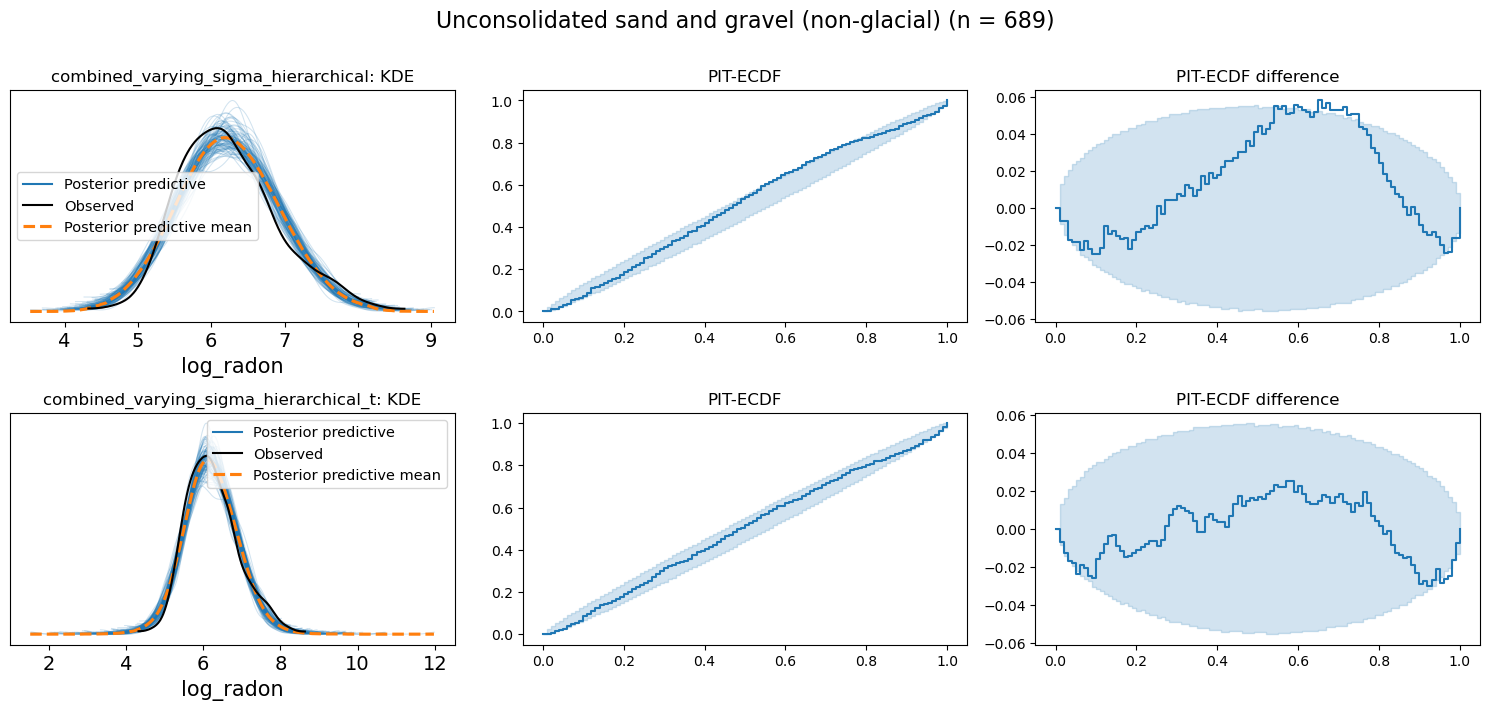

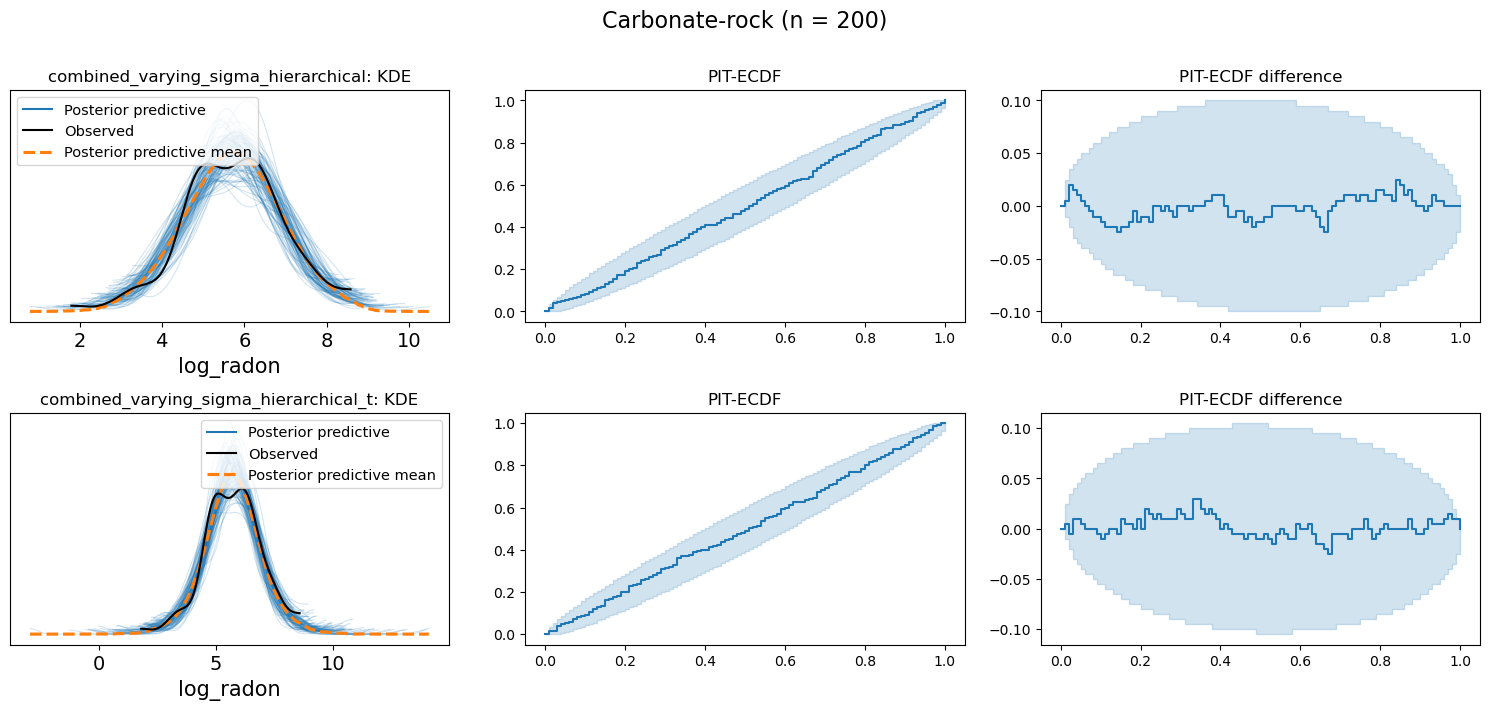

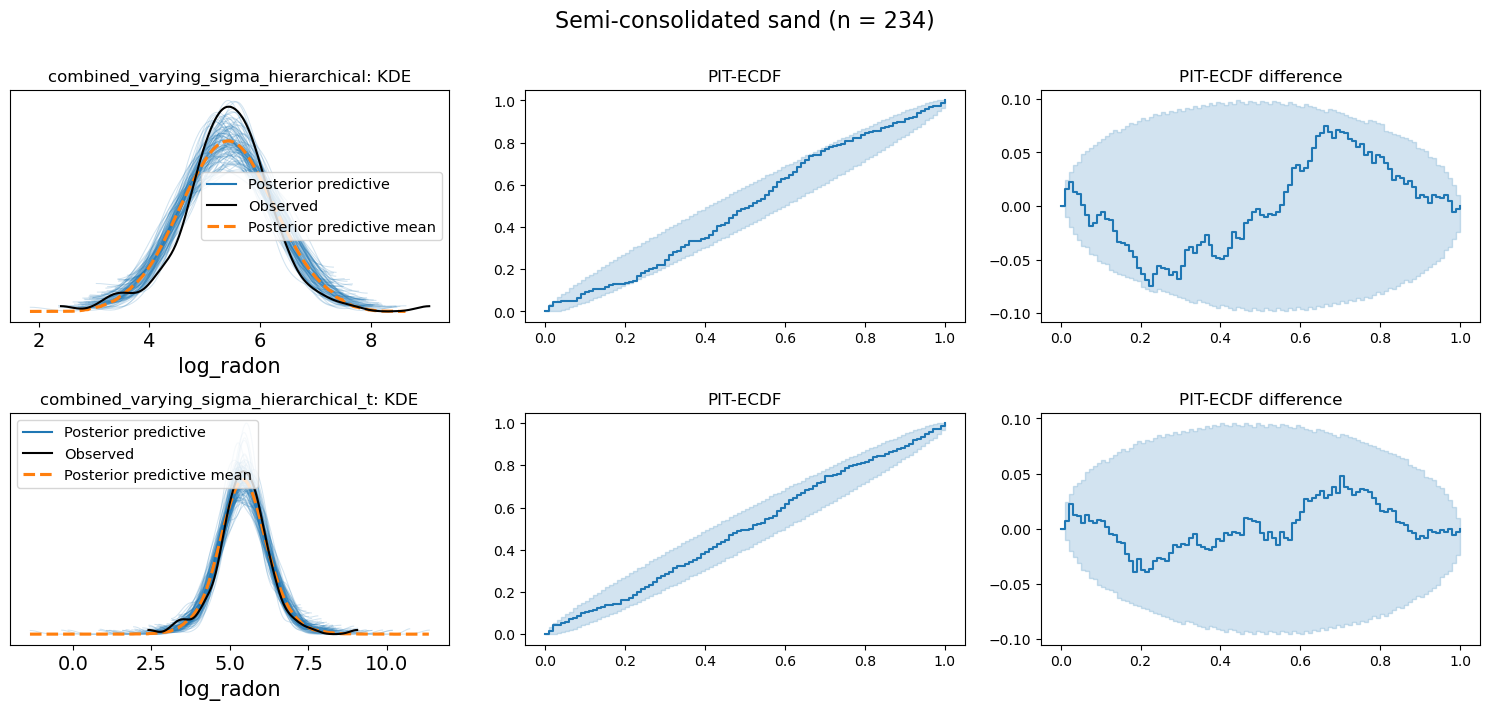

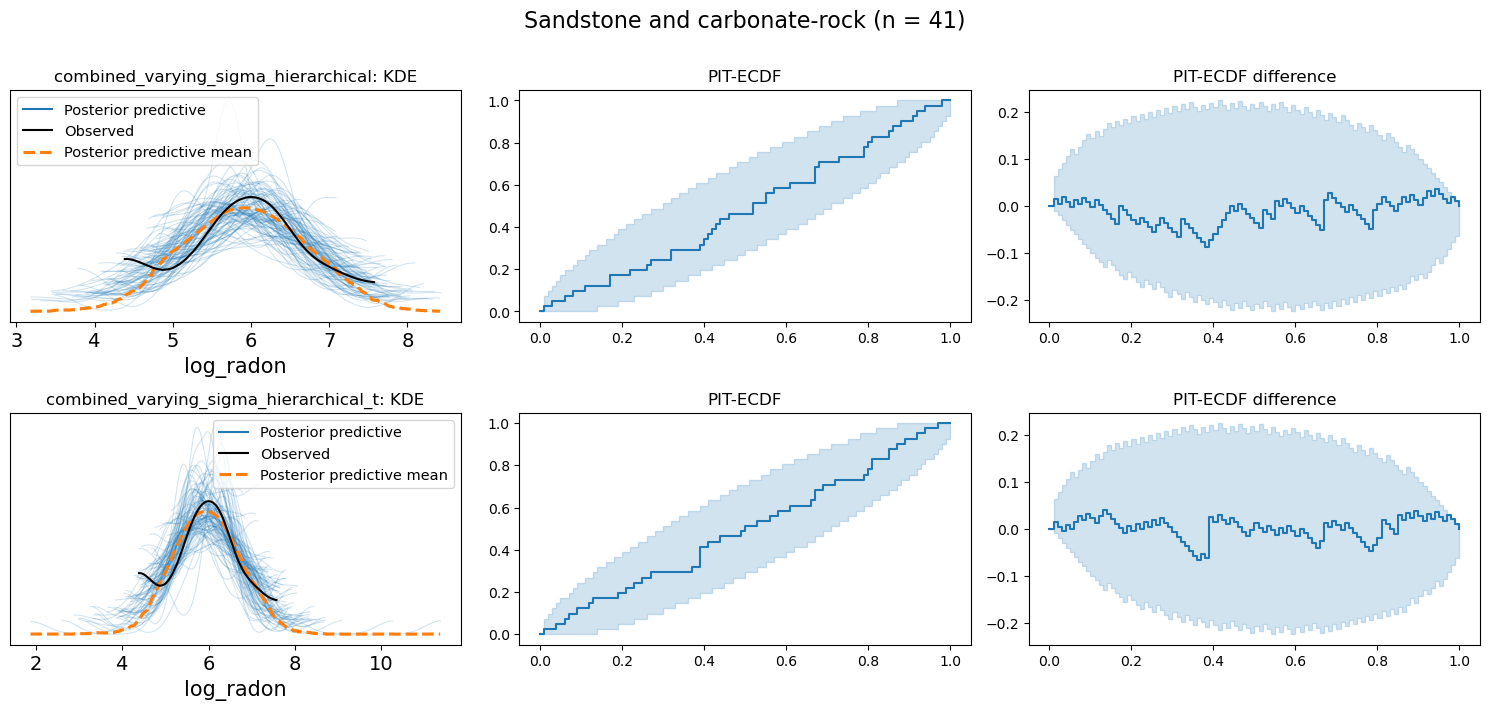

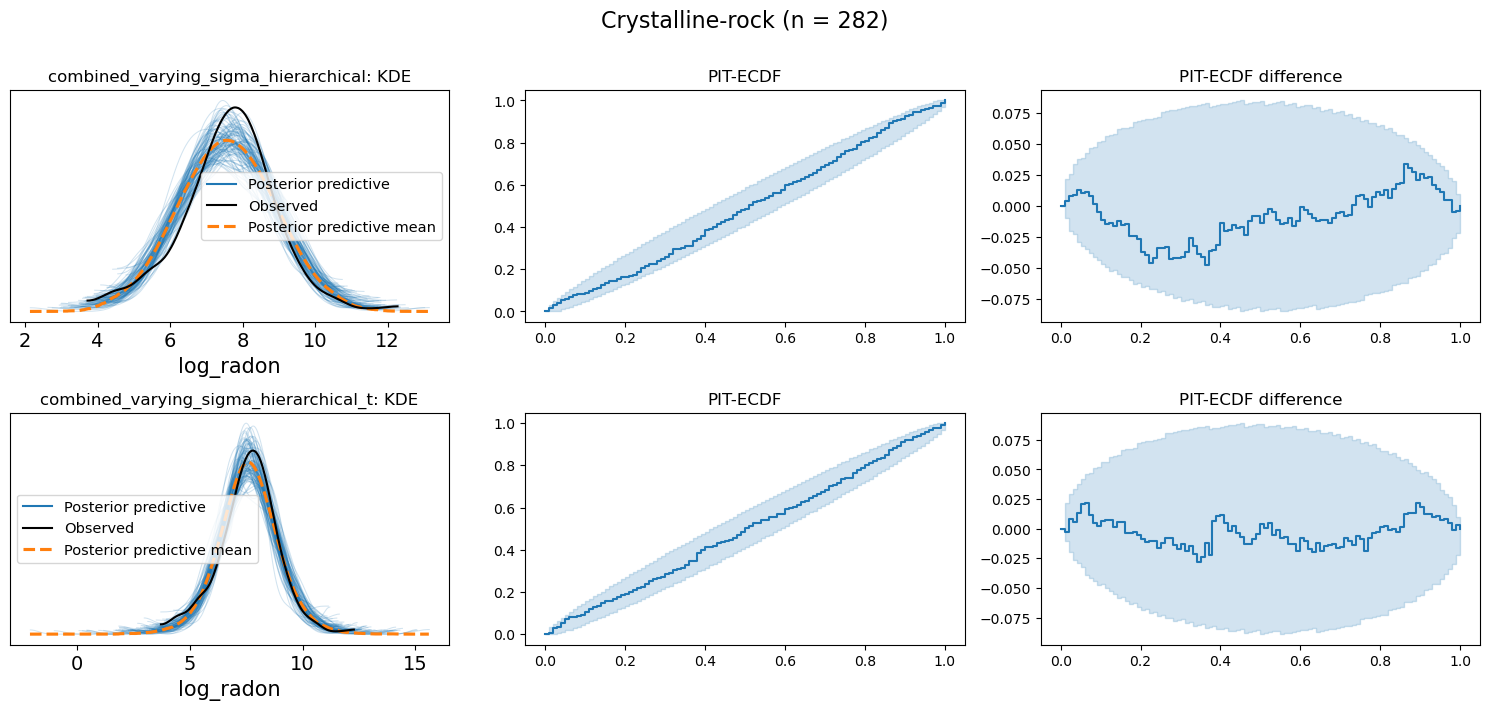

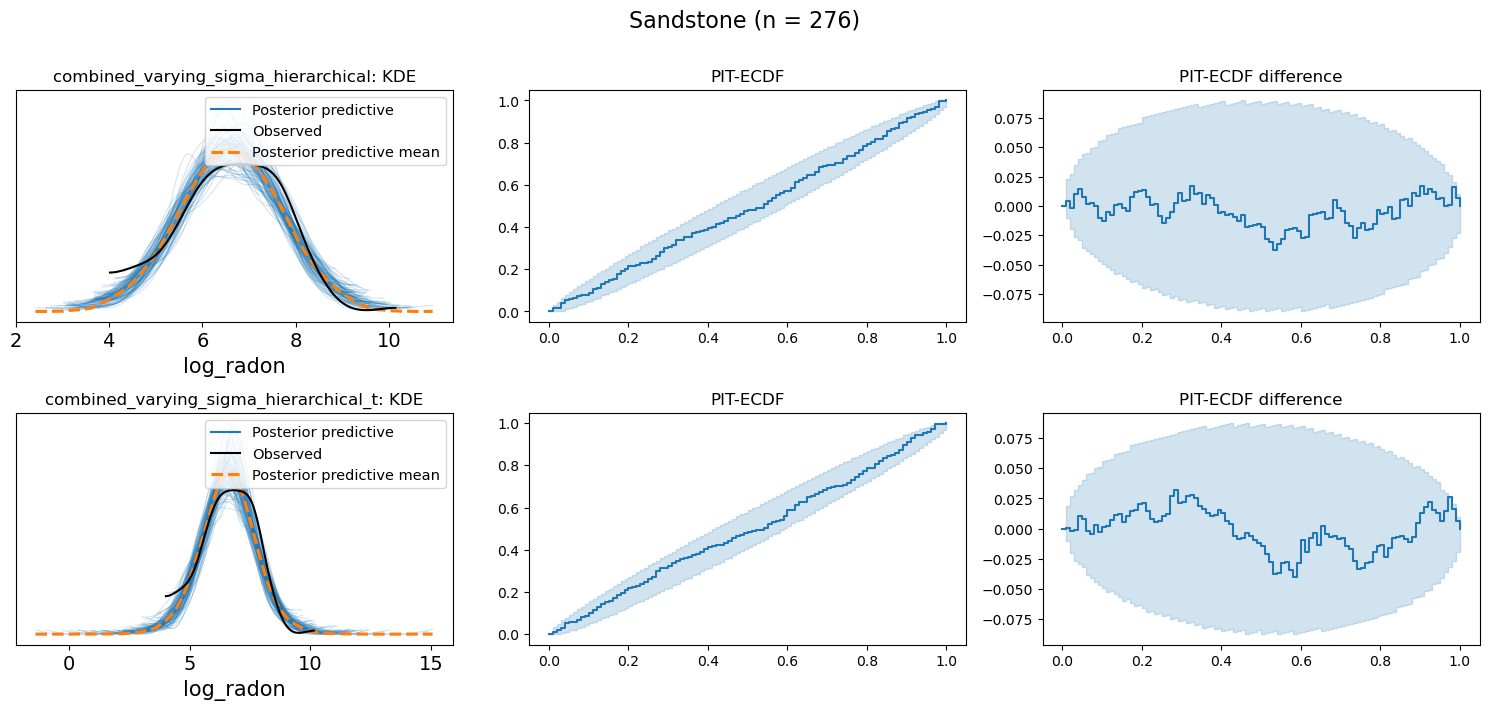

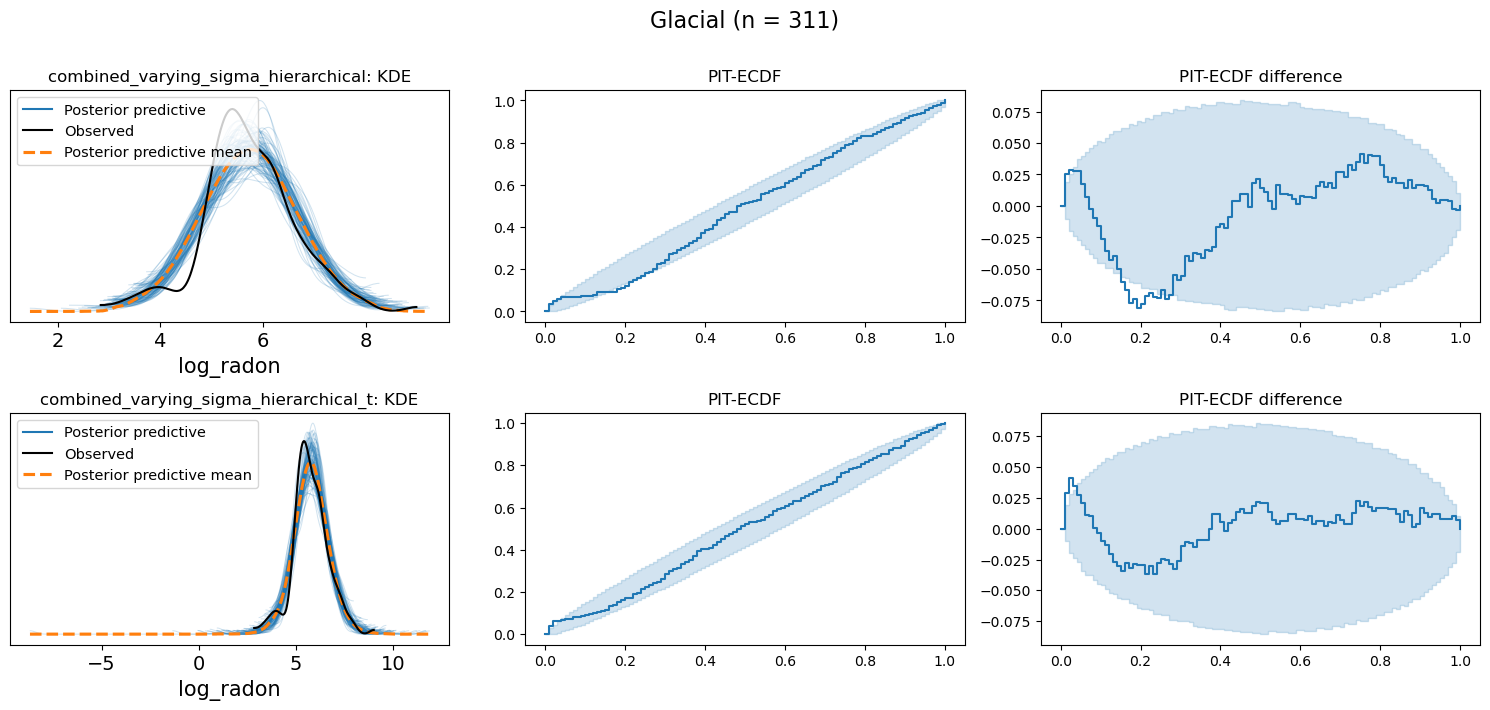

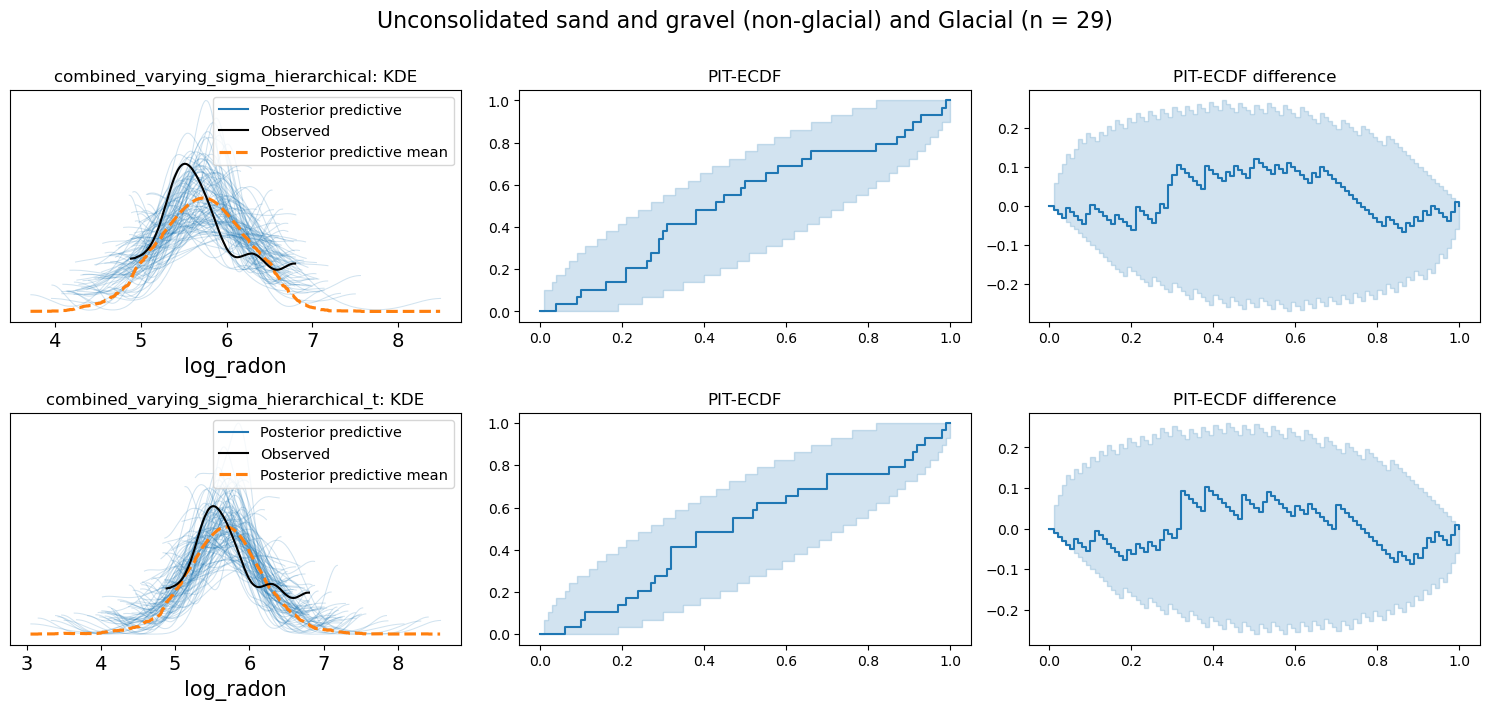

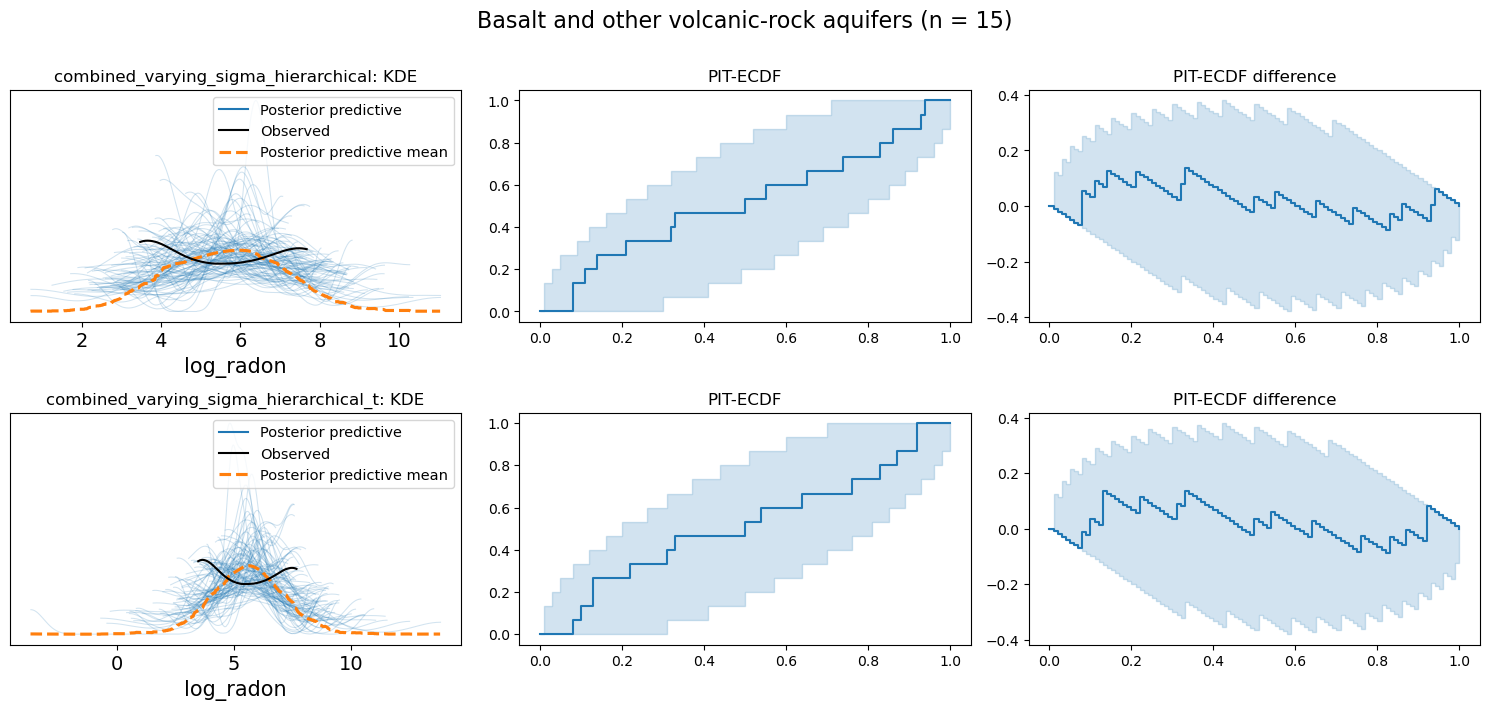

In [37]:
def plot_predictive_checks(fits, y_name="log_radon", obs_idx=None,
                           ci_prob=0.95, num_pp_samples=100, title=None):
    """KDE, PIT-ECDF and PIT-ECDF difference for several fits, one row per model.

    fits: dict {name: InferenceData with posterior_predictive and log_likelihood}
    obs_idx: optional array of observation positions, e.g. one lithology
    title: optional figure title, e.g. the lithology name
    """
    fig, axes = plt.subplots(len(fits), 3, figsize=(15, 3.6 * len(fits)), squeeze=False)
    eval_points = np.linspace(0, 1, 101)
    coords = {"__obs__": obs_idx} if obs_idx is not None else None

    for row, (name, fit) in enumerate(fits.items()):
        az.plot_ppc(fit, var_names=[y_name], coords=coords,
                    num_pp_samples=num_pp_samples, ax=axes[row, 0])

        pit = np.asarray(az.loo_pit(fit, y=y_name)).ravel()
        if obs_idx is not None:
            pit = pit[obs_idx]

        for ax, difference in zip(axes[row, 1:], [False, True]):
            az.plot_ecdf(pit, cdf=st.uniform().cdf, rvs=st.uniform().rvs, eval_points=eval_points,
                         confidence_bands="simulated", ci_prob=ci_prob,
                         difference=difference, ax=ax)

        axes[row, 0].set_title(f"{name}: KDE")
        axes[row, 1].set_title("PIT-ECDF")
        axes[row, 2].set_title("PIT-ECDF difference")

    if title is not None:
        fig.suptitle(title, fontsize=16)
        fig.tight_layout(rect=(0, 0, 1, 0.97))   # leave room for the title
    else:
        fig.tight_layout()
    plt.show()
    return fig


fits_good = {name: fit for name, (model, fit) in fits_and_models_good.items()}

for lith in df["lithology"].unique():
    idx = np.where(df["lithology"].values == lith)[0]
    plot_predictive_checks(fits_good, obs_idx=idx, title=f"{lith} (n = {len(idx)})");


In [43]:
def convergence_summary(fits, decimals=3):
    """Divergences, worst R-hat and smallest ESS over all parameters, per model."""
    rows = []
    for name, fit in fits.items():
        # skip per-observation quantities added by predict (mu, sigma per well)
        params = [v for v in fit.posterior.data_vars
                  if "__obs__" not in fit.posterior[v].dims]
        s = az.summary(fit, var_names=params, kind="diagnostics", round_to="none")
        rows.append({
            "model": name,
            "divergences": int(fit.sample_stats["diverging"].sum()),
            "max_rhat": s["r_hat"].max(),
            "max_rhat_param": s["r_hat"].idxmax(),
            "min_ess_bulk": s["ess_bulk"].min(),
            "min_ess_bulk_param": s["ess_bulk"].idxmin(),
            "min_ess_tail": s["ess_tail"].min(),
            "min_ess_tail_param": s["ess_tail"].idxmin(),
        })
    out = pd.DataFrame(rows).set_index("model")
    out["max_rhat"] = out["max_rhat"].round(decimals)
    out[["min_ess_bulk", "min_ess_tail"]] = out[["min_ess_bulk", "min_ess_tail"]].round(0).astype(int)
    return out

with pd.option_context("display.width", 200, "display.max_columns", None):
    print(convergence_summary({name: fit for name, (model, fit) in fits_and_models.items()}))

                                       divergences  max_rhat                                     max_rhat_param  min_ess_bulk      min_ess_bulk_param  min_ess_tail  \
model                                                                                                                                                                 
pooled                                           0     1.001                                          Intercept          5584               Intercept          2835   
pooled_t                                         0     1.001                                                 nu          2565                      nu          2187   
aquifer_hierarchical                             0     1.005                                    1|aquifer_sigma           959               Intercept          2123   
combined_hierarchical                            0     1.005                                    1|aquifer_sigma          1010         1|aquifer_sigma          1828  